# Detecção de fraude em transações de cartão de crédito

**Desafio de Projeto — DIO**

Este notebook percorre o pipeline completo de um modelo de detecção de fraude: exploração dos dados, preparação, treino de três algoritmos, avaliação pelas métricas que importam, ajuste de limiar, busca de hiperparâmetros, interpretação com SHAP e comparação de estratégias de balanceamento.

Se estiver no **Google Colab**, as bibliotecas `shap`, `imbalanced-learn` e `xgboost` não estão instaladas por padrão. A célula abaixo as instala automaticamente. No ambiente local com `mise` + `uv`, ela não faz nada.

In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install -q shap imbalanced-learn xgboost

## 1. Configuração

Importamos as bibliotecas, definimos a semente aleatória para reprodutibilidade e criamos as pastas onde as figuras e as métricas serão salvas.

In [2]:
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

Path("images").mkdir(exist_ok=True)
Path("resultados").mkdir(exist_ok=True)

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 12

## 2. Exploração dos dados

O notebook lê o CSV **diretamente pela URL**, como no desafio. O arquivo tem cerca de 144 MB e não deve ser versionado no repositório.

In [3]:
df = pd.read_csv(DATA_URL)

print(f"Transações: {df.shape[0]:,}".replace(",", "."))
print(f"Colunas: {df.shape[1]}")
df.head()

Transações: 284.807
Colunas: 31


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### Qualidade dos dados

Antes de modelar, verificamos valores nulos e linhas duplicadas. Duplicatas podem aparecer ao mesmo tempo no treino e no teste, inflando as métricas, então vamos removê-las e registrar o impacto.

In [4]:
print(f"Valores nulos: {int(df.isna().sum().sum())}")
print(f"Linhas duplicadas: {int(df.duplicated().sum())}")
print(f"Fraudes entre as duplicadas: {int(df.loc[df.duplicated(), 'Class'].sum())}")

df[["Time", "Amount", "Class"]].describe().round(2)

Valores nulos: 0


Linhas duplicadas: 1081


Fraudes entre as duplicadas: 19


,Time,Amount,Class
count,284807.00,284807.00,284807.00
mean,94813.86,88.35,0.00
std,47488.15,250.12,0.04
min,0.00,0.00,0.00
25%,54201.50,5.60,0.00
50%,84692.00,22.00,0.00
75%,139320.50,77.16,0.00
max,172792.00,25691.16,1.00


In [5]:
df = df.drop_duplicates().reset_index(drop=True)
print(f"Base após remover duplicadas: {df.shape[0]:,} transações".replace(",", "."))

contagem = df["Class"].value_counts().sort_index()
percentual = df["Class"].value_counts(normalize=True).sort_index() * 100

tabela_classes = pd.DataFrame({
    "Classe": ["Normal (0)", "Fraude (1)"],
    "Transações": contagem.values,
    "Percentual (%)": percentual.round(4).values,
})
tabela_classes

Base após remover duplicadas: 283.726 transações


,Classe,Transações,Percentual (%)
0,Normal (0),283253,99.8333
1,Fraude (1),473,0.1667


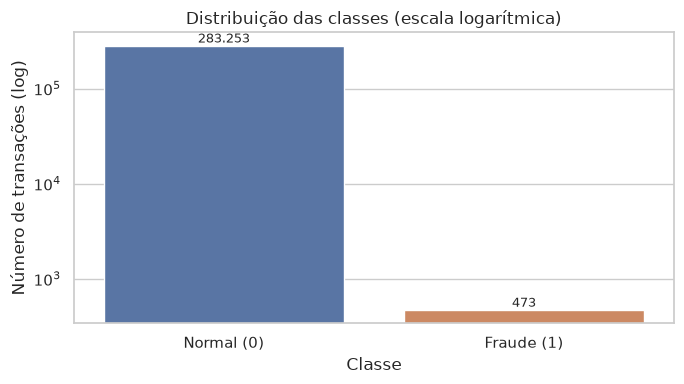

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(7, 4))
barras = sns.barplot(
    data=tabela_classes,
    x="Classe",
    y="Transações",
    hue="Classe",
    legend=False,
    ax=ax,
)
ax.set_yscale("log")
ax.set_title("Distribuição das classes (escala logarítmica)")
ax.set_ylabel("Número de transações (log)")
for barra, valor in zip(barras.patches, tabela_classes["Transações"]):
    ax.annotate(
        f"{valor:,}".replace(",", "."),
        (barra.get_x() + barra.get_width() / 2, barra.get_height()),
        ha="center",
        va="bottom",
        fontsize=9,
    )
plt.tight_layout()
plt.savefig("images/01_distribuicao_classes.png", dpi=150, bbox_inches="tight")
plt.show()

### Amount por classe

A distribuição de valores é muito assimétrica. Por isso, aplicamos `np.log1p` no valor antes de padronizar: o log comprime os valores altos e deixa a escala mais próxima de uma distribuição normal.

In [7]:
df["Amount_log"] = np.log1p(df["Amount"])

features = [f"V{i}" for i in range(1, 29)] + ["Time", "Amount_log"]
X = df[features]
y = df["Class"]

print(f"{len(features)} variáveis preditoras")
print(features)

30 variáveis preditoras
['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Time', 'Amount_log']


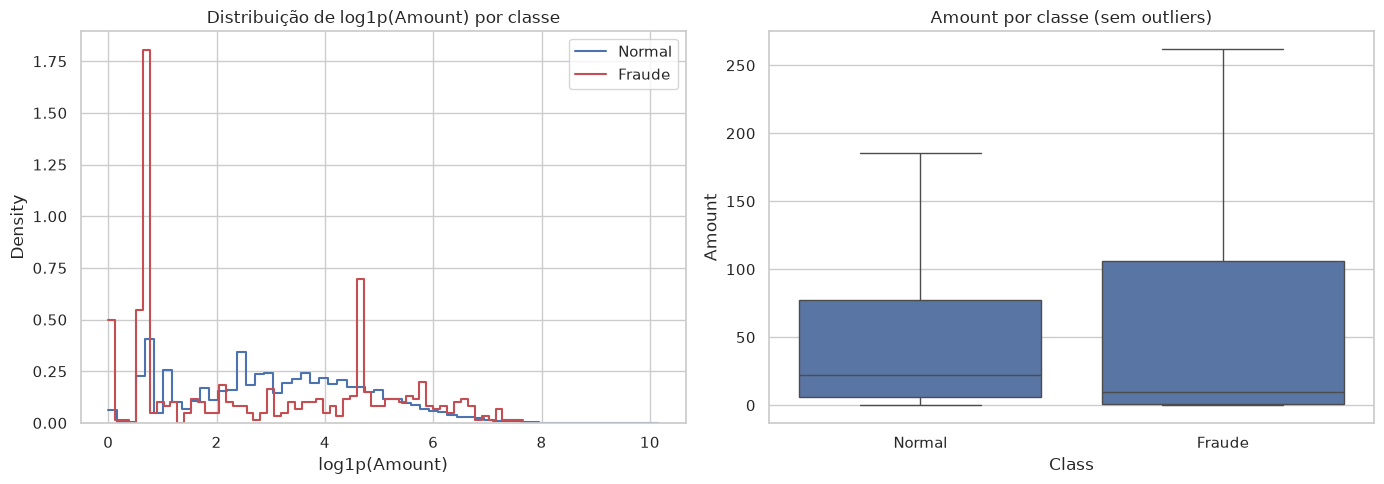

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.41,250.38,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.87,260.21,0.0,1.00,9.82,105.89,2125.87


In [8]:
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for classe, rotulo, cor in [(0, "Normal", "#4c72b0"), (1, "Fraude", "#c44e52")]:
    valores = np.log1p(df.loc[df["Class"] == classe, "Amount"])
    sns.histplot(
        valores,
        bins=60,
        stat="density",
        element="step",
        fill=False,
        label=rotulo,
        color=cor,
        ax=axes[0],
    )
axes[0].set_title("Distribuição de log1p(Amount) por classe")
axes[0].set_xlabel("log1p(Amount)")
axes[0].legend()

sns.boxplot(data=df, x="Class", y="Amount", ax=axes[1], showfliers=False)
axes[1].set_xticks([0, 1], ["Normal", "Fraude"])
axes[1].set_title("Amount por classe (sem outliers)")
axes[1].set_ylabel("Amount")

plt.tight_layout()
plt.savefig("images/02_amount_por_classe.png", dpi=150, bbox_inches="tight")
plt.show()

df.groupby("Class")["Amount"].describe().round(2)

### Fraudes ao longo do tempo

`Time` é o tempo em segundos desde a primeira transação da base, cobrindo cerca de 48 horas.

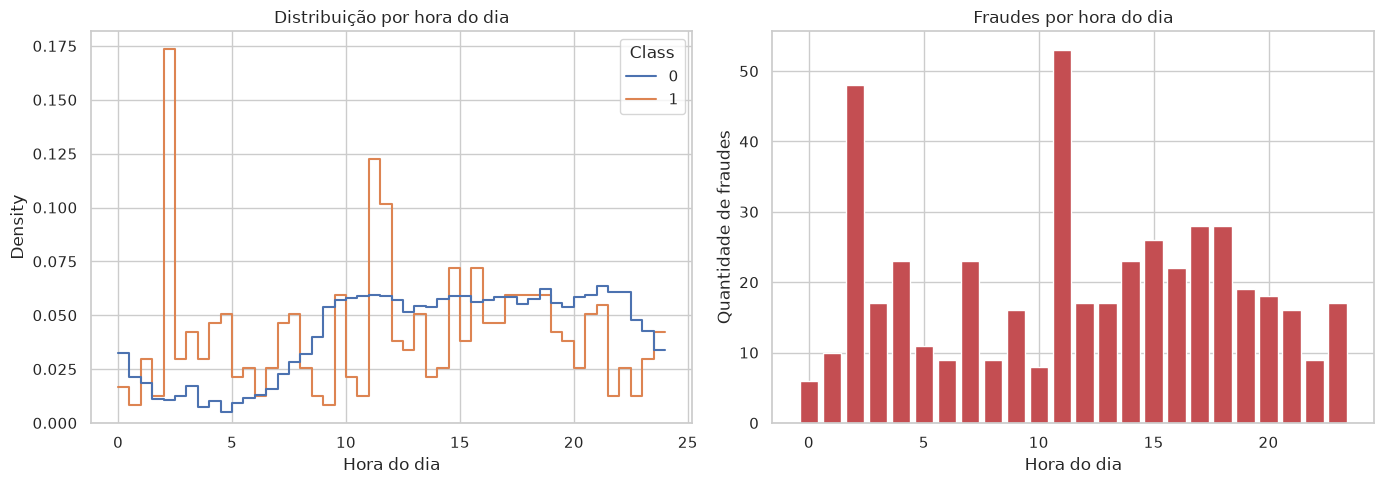

In [9]:
df["Hora"] = (df["Time"] / 3600) % 24

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x="Hora",
    hue="Class",
    bins=48,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    ax=axes[0],
)
axes[0].set_title("Distribuição por hora do dia")
axes[0].set_xlabel("Hora do dia")

fraudes_por_hora = df[df["Class"] == 1].groupby(df["Hora"].astype(int)).size()
axes[1].bar(fraudes_por_hora.index, fraudes_por_hora.values, color="#c44e52")
axes[1].set_title("Fraudes por hora do dia")
axes[1].set_xlabel("Hora do dia")
axes[1].set_ylabel("Quantidade de fraudes")

plt.tight_layout()
plt.savefig("images/03_fraudes_por_hora.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Preparação dos dados

Criamos `Amount_log` com `np.log1p` e mantemos `Time` e as 28 componentes principais. A padronização fica **dentro de um `Pipeline`**, ajustada apenas no treino, para evitar vazamento de informação do teste.

In [10]:
df["Amount_log"] = np.log1p(df["Amount"])

features = [f"V{i}" for i in range(1, 29)] + ["Time", "Amount_log"]
X = df[features]
y = df["Class"]

print(f"{len(features)} variáveis preditoras")
print(features)

30 variáveis preditoras
['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Time', 'Amount_log']


### Separação treino/teste

Usamos 80% para treino e 20% para teste, com `stratify=y` para manter a mesma proporção de fraudes nos dois conjuntos.

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

resumo_split = pd.DataFrame(
    {
        "Treino": [len(y_train), int(y_train.sum()), 100 * y_train.mean()],
        "Teste": [len(y_test), int(y_test.sum()), 100 * y_test.mean()],
    },
    index=["Transações", "Fraudes", "Percentual de fraude (%)"],
).round(4)
resumo_split

,Treino,Teste
Transações,226980.0000,56746.0000
Fraudes,378.0000,95.0000
Percentual de fraude (%),0.1665,0.1674


In [12]:
from sklearn.preprocessing import StandardScaler

scaler_demo = StandardScaler()
X_train_scaled = scaler_demo.fit_transform(X_train)
X_test_scaled = scaler_demo.transform(X_test)

print("Média das 5 primeiras variáveis no treino padronizado:")
print(np.round(X_train_scaled[:, :5].mean(axis=0), 6))
print("Desvio-padrão das 5 primeiras variáveis no treino padronizado:")
print(np.round(X_train_scaled[:, :5].std(axis=0), 6))
print("Formatos:", X_train_scaled.shape, X_test_scaled.shape)

Média das 5 primeiras variáveis no treino padronizado:
[ 0. -0.  0. -0.  0.]
Desvio-padrão das 5 primeiras variáveis no treino padronizado:
[1. 1. 1. 1. 1.]
Formatos: (226980, 30) (56746, 30)


## 4. Modelos e avaliação

Vamos comparar três algoritmos:

1. **Regressão logística** como baseline, com `class_weight='balanced'`;
2. **Random Forest**, também com `class_weight='balanced'`;
3. **XGBoost**, usando `scale_pos_weight` para dar mais peso à fraude.

In [13]:
resultados = []
probas = {}


def avaliar_modelo(nome, modelo, limiar=0.5, registrar=True, chave=None):
    chave = chave or nome
    proba = modelo.predict_proba(X_test)[:, 1]
    pred = (proba >= limiar).astype(int)
    probas[chave] = proba

    from sklearn.metrics import (
        precision_score, recall_score, f1_score,
        roc_auc_score, average_precision_score,
        classification_report, confusion_matrix
    )
    from sklearn.metrics import ConfusionMatrixDisplay

    metricas = {
        "Modelo": nome,
        "Limiar": limiar,
        "Precisão": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, proba),
        "PR AUC": average_precision_score(y_test, proba),
    }

    print(f"=== {nome} | limiar = {limiar:.2f} ===")
    print(
        classification_report(
            y_test,
            pred,
            target_names=["Normal", "Fraude"],
            digits=4,
        )
    )

    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["Normal", "Fraude"])
    fig, ax = plt.subplots(figsize=(5, 4))
    disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"Matriz de confusão — {nome} (limiar {limiar:.2f})")
    plt.tight_layout()
    plt.show()

    if registrar:
        resultados.append(metricas)

    return metricas

### Baseline: regressão logística

=== Regressão Logística | limiar = 0.50 ===
              precision    recall  f1-score   support

      Normal     0.9998    0.9750    0.9872     56651
      Fraude     0.0554    0.8737    0.1042        95

    accuracy                         0.9749     56746
   macro avg     0.5276    0.9244    0.5457     56746
weighted avg     0.9982    0.9749    0.9858     56746



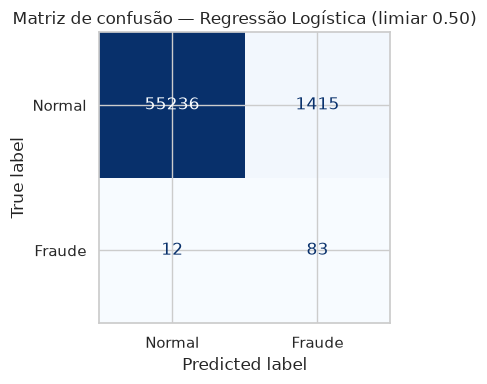

{'Modelo': 'Regressão Logística',
 'Limiar': 0.5,
 'Precisão': 0.05540720961281709,
 'Recall': 0.8736842105263158,
 'F1': 0.10420590081607031,
 'ROC AUC': 0.9625185229229011,
 'PR AUC': 0.6770191241222574}

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

modelo_lr = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)
modelo_lr.fit(X_train, y_train)
avaliar_modelo("Regressão Logística", modelo_lr)

### Random Forest

=== Random Forest | limiar = 0.50 ===
              precision    recall  f1-score   support

      Normal     0.9995    0.9999    0.9997     56651
      Fraude     0.9583    0.7263    0.8263        95

    accuracy                         0.9995     56746
   macro avg     0.9789    0.8631    0.9130     56746
weighted avg     0.9995    0.9995    0.9995     56746



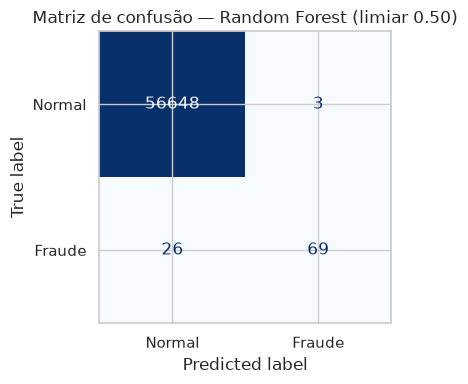

{'Modelo': 'Random Forest',
 'Limiar': 0.5,
 'Precisão': 0.9583333333333334,
 'Recall': 0.7263157894736842,
 'F1': 0.8263473053892215,
 'ROC AUC': 0.9477524900847201,
 'PR AUC': 0.8092650045591527}

In [15]:
from sklearn.ensemble import RandomForestClassifier

modelo_rf = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                class_weight="balanced",
                n_jobs=-1,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)
modelo_rf.fit(X_train, y_train)
avaliar_modelo("Random Forest", modelo_rf)

### XGBoost

O XGBoost não tem `class_weight`, então usamos `scale_pos_weight`: a razão entre o número de transações normais e de fraudes no treino.

scale_pos_weight = 599.48


=== XGBoost | limiar = 0.50 ===
              precision    recall  f1-score   support

      Normal     0.9997    0.9998    0.9997     56651
      Fraude     0.8556    0.8105    0.8324        95

    accuracy                         0.9995     56746
   macro avg     0.9276    0.9051    0.9161     56746
weighted avg     0.9994    0.9995    0.9994     56746



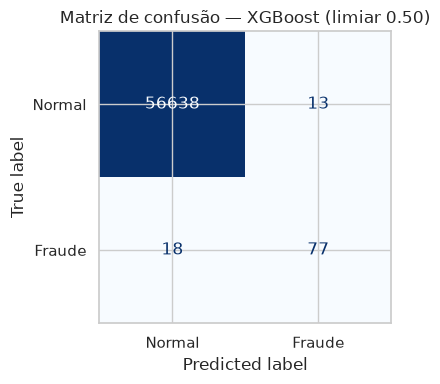

{'Modelo': 'XGBoost',
 'Limiar': 0.5,
 'Precisão': 0.8555555555555555,
 'Recall': 0.8105263157894737,
 'F1': 0.8324324324324325,
 'ROC AUC': 0.9752496588065989,
 'PR AUC': 0.8187680501779493}

In [16]:
from xgboost import XGBClassifier

escala_pos = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {escala_pos:.2f}")

modelo_xgb = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "model",
            XGBClassifier(
                n_estimators=300,
                learning_rate=0.05,
                max_depth=5,
                subsample=0.8,
                colsample_bytree=0.8,
                scale_pos_weight=escala_pos,
                eval_metric="aucpr",
                tree_method="hist",
                n_jobs=-1,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)
modelo_xgb.fit(X_train, y_train)
avaliar_modelo("XGBoost", modelo_xgb)

### Comparação dos modelos

A tabela abaixo ordena os modelos pelo **recall** da classe de fraude.

In [17]:
import pandas as pd

tabela_modelos = (
    pd.DataFrame(resultados)
    .set_index("Modelo")
    .sort_values("Recall", ascending=False)
)
tabela_modelos.round(4).to_csv("resultados/metricas_modelos.csv", index=True)
tabela_modelos.style.format("{:.4f}").background_gradient(
    cmap="Blues", subset=["Recall", "F1", "PR AUC"]
)

,Limiar,Precisão,Recall,F1,ROC AUC,PR AUC
Modelo,,,,,,
Regressão Logística,0.5000,0.0554,0.8737,0.1042,0.9625,0.6770
XGBoost,0.5000,0.8556,0.8105,0.8324,0.9752,0.8188
Random Forest,0.5000,0.9583,0.7263,0.8263,0.9478,0.8093


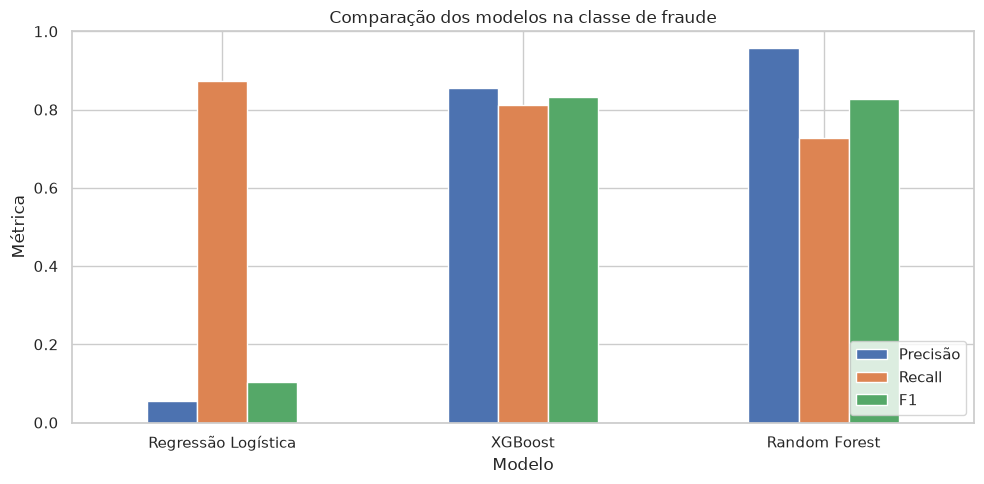

In [18]:
fig, ax = plt.subplots(figsize=(10, 5))
tabela_modelos[["Precisão", "Recall", "F1"]].plot(
    kind="bar",
    ax=ax,
    color=["#4c72b0", "#dd8452", "#55a868"],
)
ax.set_title("Comparação dos modelos na classe de fraude")
ax.set_ylabel("Métrica")
ax.set_ylim(0, 1)
ax.legend(loc="lower right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("images/04_comparacao_modelos.png", dpi=150, bbox_inches="tight")
plt.show()

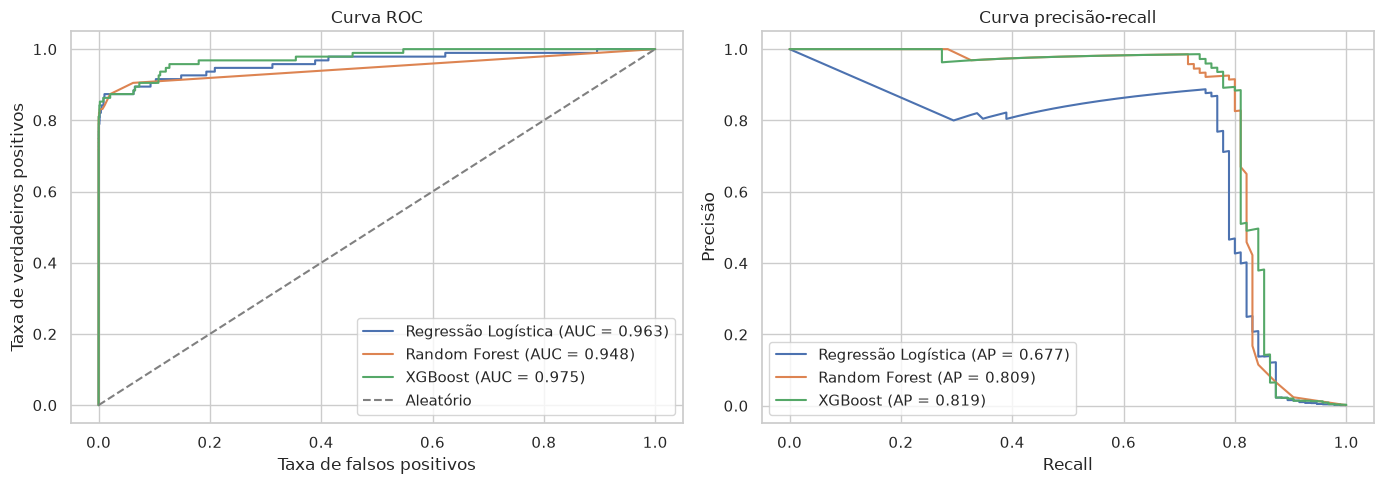

In [19]:
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for nome in ["Regressão Logística", "Random Forest", "XGBoost"]:
    proba = probas[nome]
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(
        fpr,
        tpr,
        label=f"{nome} (AUC = {roc_auc_score(y_test, proba):.3f})",
    )

    precisao, recall, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(
        recall,
        precisao,
        label=f"{nome} (AP = {average_precision_score(y_test, proba):.3f})",
    )

axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Aleatório")
axes[0].set_title("Curva ROC")
axes[0].set_xlabel("Taxa de falsos positivos")
axes[0].set_ylabel("Taxa de verdadeiros positivos")
axes[0].legend()

axes[1].set_title("Curva precisão-recall")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precisão")
axes[1].legend()

plt.tight_layout()
plt.savefig("images/05_curvas_roc_pr.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Ajuste do limiar de decisão

Por padrão, o modelo marca como fraude quando a probabilidade é maior ou igual a **0,5**. Em fraude, é comum testar um limiar mais baixo, como **0,3**, para tentar capturar mais fraudes. O efeito, porém, depende do modelo: o recall pode subir, mas a precisão costuma cair, porque mais transações normais passam a ser investigadas.

Vamos comparar o trade-off no **XGBoost** e no **Random Forest**, que têm distribuições de probabilidade diferentes.

In [20]:
import numpy as np

def tabela_por_limiar(proba):
    linhas = []
    for limiar in np.arange(0.05, 0.96, 0.05):
        pred = (proba >= limiar).astype(int)
        linhas.append(
            {
                "Limiar": limiar,
                "Precisão": precision_score(y_test, pred, zero_division=0),
                "Recall": recall_score(y_test, pred, zero_division=0),
                "F1": f1_score(y_test, pred, zero_division=0),
            }
        )
    return pd.DataFrame(linhas)


tabela_limiares_xgb = tabela_por_limiar(probas["XGBoost"])
tabela_limiares_rf = tabela_por_limiar(probas["Random Forest"])

tabela_limiares = pd.concat(
    [
        tabela_limiares_xgb.assign(Modelo="XGBoost"),
        tabela_limiares_rf.assign(Modelo="Random Forest"),
    ],
    ignore_index=True,
)
tabela_limiares.round(4).to_csv("resultados/metricas_limiares.csv", index=False)

display(tabela_limiares_xgb.round(4))
display(tabela_limiares_rf.round(4))

,Limiar,Precisão,Recall,F1
0,0.05,0.3616,0.8526,0.5078
1,0.10,0.5098,0.8211,0.6290
2,0.15,0.6063,0.8105,0.6937
3,0.20,0.6638,0.8105,0.7299
4,0.25,0.7064,0.8105,0.7549
5,0.30,0.7624,0.8105,0.7857
6,0.35,0.7778,0.8105,0.7938
7,0.40,0.8191,0.8105,0.8148
8,0.45,0.8370,0.8105,0.8235
9,0.50,0.8556,0.8105,0.8324


,Limiar,Precisão,Recall,F1
0,0.05,0.4588,0.8211,0.5887
1,0.10,0.7333,0.8105,0.7700
2,0.15,0.8105,0.8105,0.8105
3,0.20,0.8261,0.8000,0.8128
4,0.25,0.8837,0.8000,0.8398
5,0.30,0.9146,0.7895,0.8475
6,0.35,0.9231,0.7579,0.8324
7,0.40,0.9333,0.7368,0.8235
8,0.45,0.9333,0.7368,0.8235
9,0.50,0.9583,0.7263,0.8263


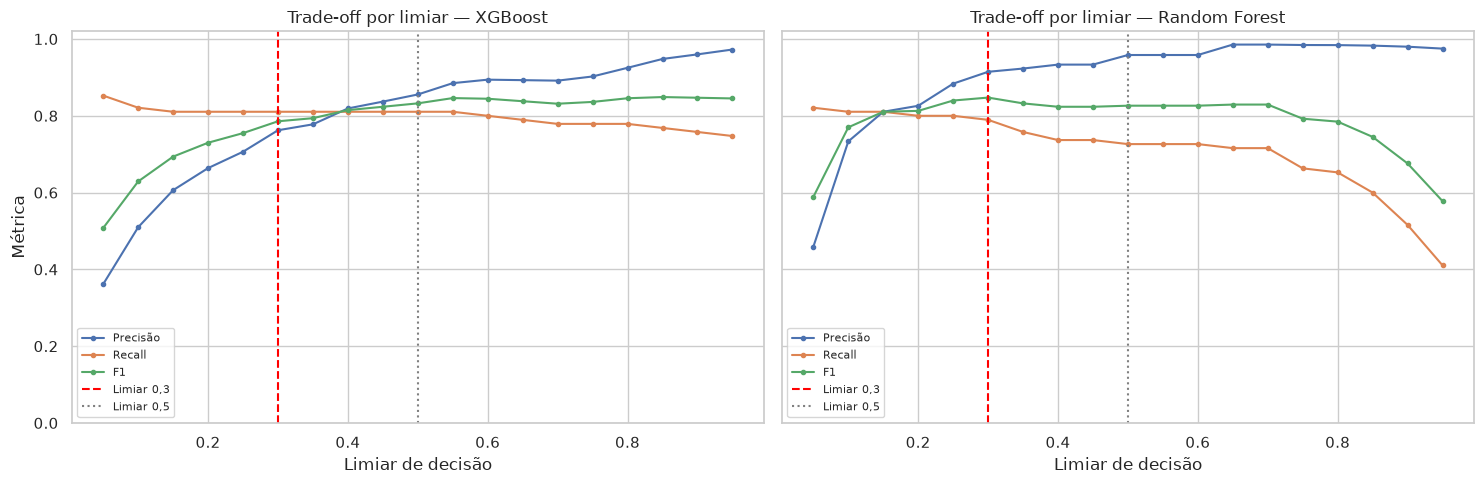

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

for ax, tabela, titulo in [
    (axes[0], tabela_limiares_xgb, "XGBoost"),
    (axes[1], tabela_limiares_rf, "Random Forest"),
]:
    for metrica, cor in [
        ("Precisão", "#4c72b0"),
        ("Recall", "#dd8452"),
        ("F1", "#55a868"),
    ]:
        ax.plot(
            tabela["Limiar"],
            tabela[metrica],
            marker="o",
            markersize=3,
            label=metrica,
            color=cor,
        )
    ax.axvline(0.3, color="red", linestyle="--", label="Limiar 0,3")
    ax.axvline(0.5, color="gray", linestyle=":", label="Limiar 0,5")
    ax.set_title(f"Trade-off por limiar — {titulo}")
    ax.set_xlabel("Limiar de decisão")
    ax.set_ylim(0, 1.02)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Métrica")
plt.tight_layout()
plt.savefig("images/06_limiar_decisao.png", dpi=150, bbox_inches="tight")
plt.show()

=== XGBoost (limiar 0,3) | limiar = 0.30 ===
              precision    recall  f1-score   support

      Normal     0.9997    0.9996    0.9996     56651
      Fraude     0.7624    0.8105    0.7857        95

    accuracy                         0.9993     56746
   macro avg     0.8810    0.9051    0.8927     56746
weighted avg     0.9993    0.9993    0.9993     56746



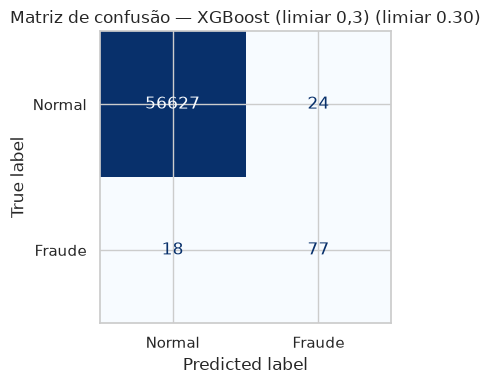

=== Random Forest (limiar 0,3) | limiar = 0.30 ===
              precision    recall  f1-score   support

      Normal     0.9996    0.9999    0.9998     56651
      Fraude     0.9146    0.7895    0.8475        95

    accuracy                         0.9995     56746
   macro avg     0.9571    0.8947    0.9236     56746
weighted avg     0.9995    0.9995    0.9995     56746



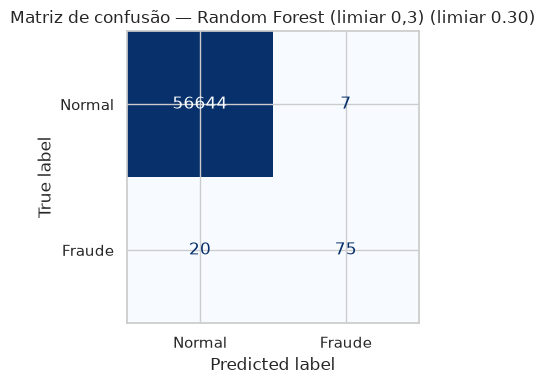

,Limiar,Precisão,Recall,F1,ROC AUC,PR AUC
Modelo,,,,,,
XGBoost,0.5,0.8556,0.8105,0.8324,0.9752,0.8188
"XGBoost (limiar 0,3)",0.3,0.7624,0.8105,0.7857,0.9752,0.8188
Random Forest,0.5,0.9583,0.7263,0.8263,0.9478,0.8093
"Random Forest (limiar 0,3)",0.3,0.9146,0.7895,0.8475,0.9478,0.8093


In [22]:
avaliar_modelo(
    "XGBoost (limiar 0,3)",
    modelo_xgb,
    limiar=0.3,
    chave="XGBoost (0.3)",
)

avaliar_modelo(
    "Random Forest (limiar 0,3)",
    modelo_rf,
    limiar=0.3,
    chave="Random Forest (0.3)",
)

candidatos_limiar = [
    "XGBoost",
    "XGBoost (limiar 0,3)",
    "Random Forest",
    "Random Forest (limiar 0,3)",
]
tabela_candidatos_limiar = (
    pd.DataFrame([r for r in resultados if r["Modelo"] in candidatos_limiar])
    .set_index("Modelo")
    .loc[candidatos_limiar]
)
tabela_candidatos_limiar.round(4)

## 6. Busca de hiperparâmetros com `GridSearchCV`

Agora colocamos padronização e XGBoost em um `Pipeline` e testamos algumas combinações de hiperparâmetros com validação cruzada estratificada. O critério de escolha é o **recall**: queremos o modelo que encontra mais fraudes.

> O `GridSearchCV` usa o limiar padrão de 0,5 para calcular o recall. Depois, aplicamos o limiar de 0,3 ao melhor modelo encontrado.

Fitting 3 folds for each of 4 candidates, totalling 12 fits


Melhores parâmetros: {'model__max_depth': 3, 'model__n_estimators': 200}
Melhor recall na validação cruzada: 0.8254
=== XGBoost (GridSearchCV) | limiar = 0.50 ===
              precision    recall  f1-score   support

      Normal     0.9996    0.9998    0.9997     56651
      Fraude     0.8929    0.7895    0.8380        95

    accuracy                         0.9995     56746
   macro avg     0.9463    0.8947    0.9189     56746
weighted avg     0.9995    0.9995    0.9995     56746



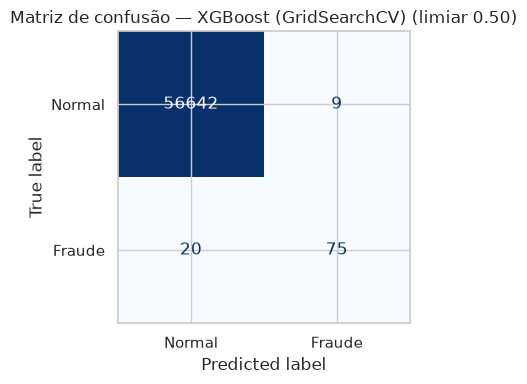

{'Modelo': 'XGBoost (GridSearchCV)',
 'Limiar': 0.5,
 'Precisão': 0.8928571428571429,
 'Recall': 0.7894736842105263,
 'F1': 0.8379888268156425,
 'ROC AUC': 0.9713627947293167,
 'PR AUC': 0.8344886794082921}

In [23]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

pipeline_busca = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "model",
            XGBClassifier(
                eval_metric="aucpr",
                scale_pos_weight=escala_pos,
                tree_method="hist",
                n_jobs=1,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

grade = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [3, 6],
}

busca = GridSearchCV(
    pipeline_busca,
    grade,
    scoring="recall",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=4,
    verbose=1,
)
busca.fit(X_train, y_train)

print("Melhores parâmetros:", busca.best_params_)
print(f"Melhor recall na validação cruzada: {busca.best_score_:.4f}")

modelo_busca = busca.best_estimator_
avaliar_modelo("XGBoost (GridSearchCV)", modelo_busca)

=== XGBoost GridSearchCV (limiar 0,3) | limiar = 0.30 ===
              precision    recall  f1-score   support

      Normal     0.9997    0.9997    0.9997     56651
      Fraude     0.8404    0.8316    0.8360        95

    accuracy                         0.9995     56746
   macro avg     0.9201    0.9157    0.9179     56746
weighted avg     0.9995    0.9995    0.9995     56746



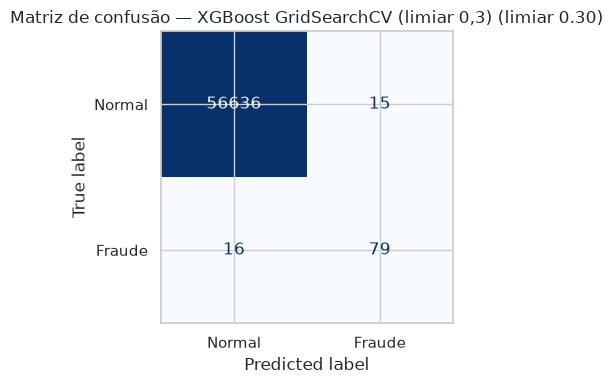

,Limiar,Precisão,Recall,F1,ROC AUC,PR AUC
Modelo,,,,,,
"XGBoost GridSearchCV (limiar 0,3)",0.3000,0.8404,0.8316,0.8360,0.9714,0.8345
XGBoost,0.5000,0.8556,0.8105,0.8324,0.9752,0.8188
"XGBoost (limiar 0,3)",0.3000,0.7624,0.8105,0.7857,0.9752,0.8188
"Random Forest (limiar 0,3)",0.3000,0.9146,0.7895,0.8475,0.9478,0.8093
XGBoost (GridSearchCV),0.5000,0.8929,0.7895,0.8380,0.9714,0.8345
Random Forest,0.5000,0.9583,0.7263,0.8263,0.9478,0.8093


In [24]:
avaliar_modelo(
    "XGBoost GridSearchCV (limiar 0,3)",
    modelo_busca,
    limiar=0.3,
    chave="XGBoost GridSearchCV (0.3)",
)

candidatos_finais = [
    "XGBoost",
    "XGBoost (limiar 0,3)",
    "Random Forest",
    "Random Forest (limiar 0,3)",
    "XGBoost (GridSearchCV)",
    "XGBoost GridSearchCV (limiar 0,3)",
]
tabela_finais = (
    pd.DataFrame([r for r in resultados if r["Modelo"] in candidatos_finais])
    .set_index("Modelo")
    .loc[candidatos_finais]
    .sort_values("Recall", ascending=False)
)
tabela_finais.round(4).to_csv("resultados/metricas_finais.csv", index=True)
tabela_finais.style.format("{:.4f}").background_gradient(
    cmap="Blues", subset=["Recall", "F1", "PR AUC"]
)

## 7. Importância das variáveis e SHAP

A importância nativa do XGBoost mostra quais variáveis o modelo mais usou nas divisões das árvores. O SHAP vai além: mostra **quanto** cada variável empurrou uma predição específica para fraude ou para normal.

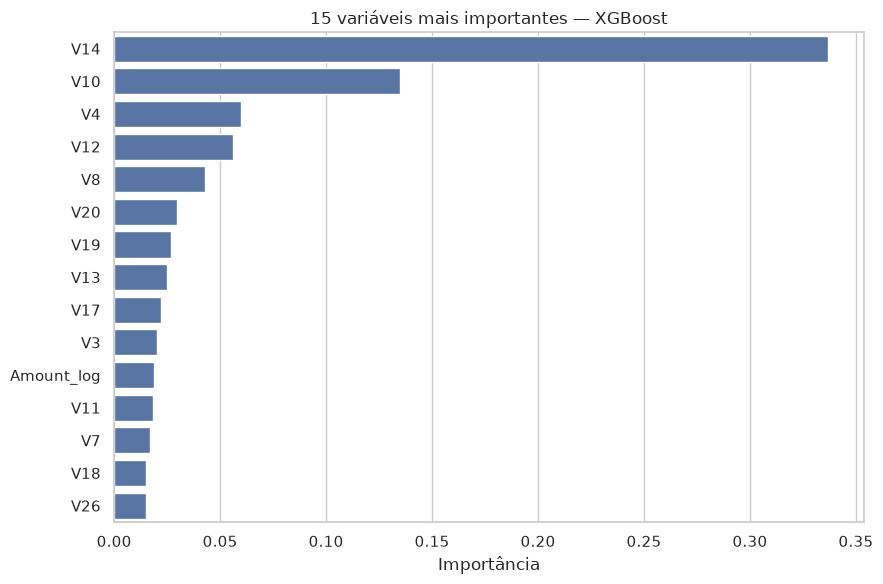

V14           0.3368
V10           0.1347
V4            0.0598
V12           0.0559
V8            0.0426
V20           0.0295
V19           0.0270
V13           0.0248
V17           0.0219
V3            0.0203
Amount_log    0.0189
V11           0.0183
V7            0.0171
V18           0.0149
V26           0.0149
dtype: float32

In [25]:
import shap

importancias = pd.Series(
    modelo_xgb.named_steps["model"].feature_importances_,
    index=features,
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(
    x=importancias.head(15).values,
    y=importancias.head(15).index,
    ax=ax,
    color="#4c72b0",
)
ax.set_title("15 variáveis mais importantes — XGBoost")
ax.set_xlabel("Importância")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("images/07_importancia_variaveis.png", dpi=150, bbox_inches="tight")
plt.show()

importancias.head(15).round(4)

Formato dos valores SHAP: (2000, 30)


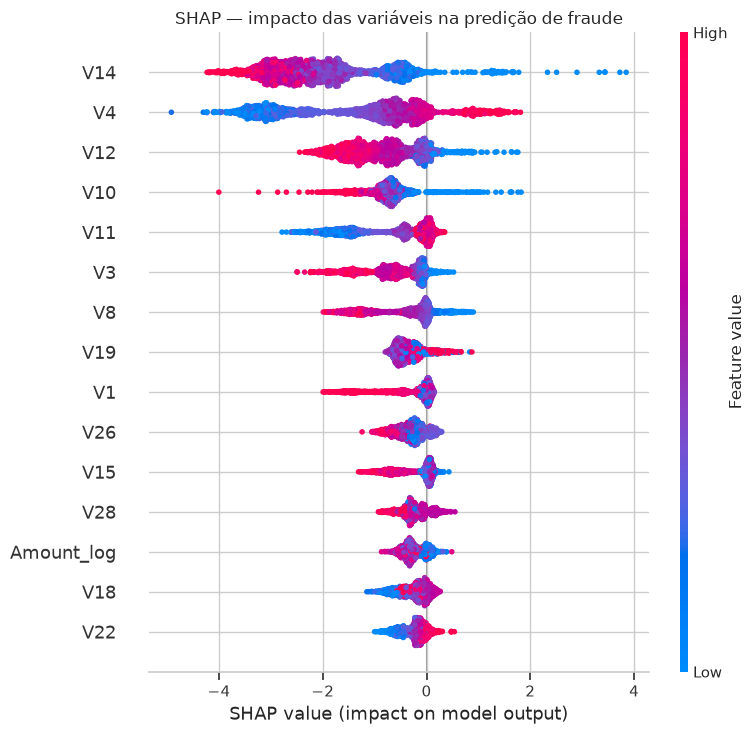

In [26]:
amostra = X_test.sample(n=min(2000, len(X_test)), random_state=RANDOM_STATE)
scaler_xgb = modelo_xgb.named_steps["scaler"]
amostra_scaled = pd.DataFrame(
    scaler_xgb.transform(amostra),
    columns=features,
    index=amostra.index,
)

explainer = shap.TreeExplainer(modelo_xgb.named_steps["model"])
shap_values = explainer.shap_values(amostra_scaled)
print("Formato dos valores SHAP:", np.shape(shap_values))

shap.summary_plot(shap_values, amostra_scaled, max_display=15, show=False)
plt.title("SHAP — impacto das variáveis na predição de fraude")
plt.tight_layout()
plt.savefig("images/08_shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

### Explicando uma fraude específica

O gráfico de waterfall mostra, para uma transação real classificada como fraude, quais variáveis aumentaram ou diminuíram a probabilidade prevista.

Transação real: fraude | probabilidade prevista: 0.9999


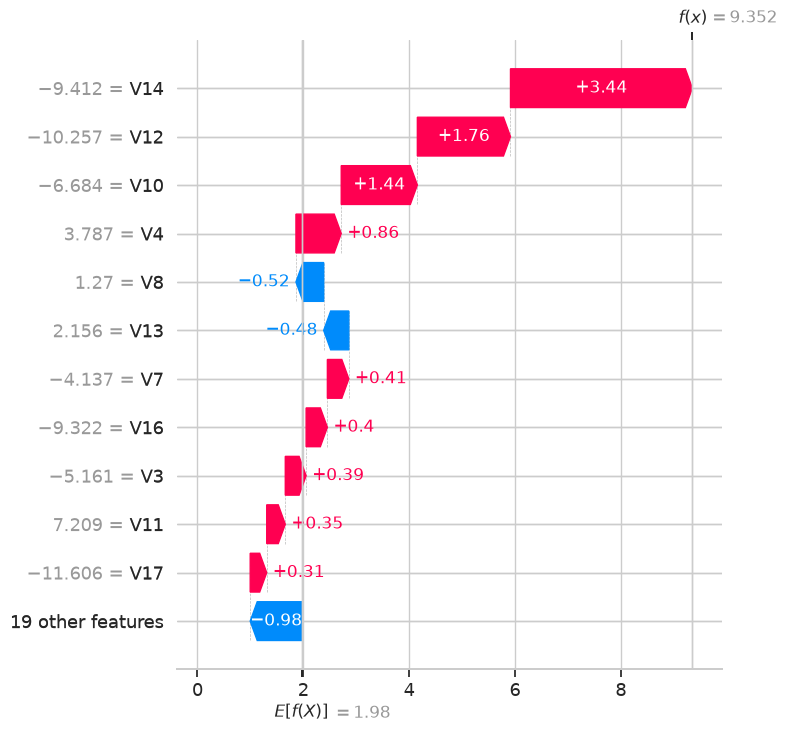

In [27]:
proba_amostra = modelo_xgb.predict_proba(amostra)[:, 1]
rotulo_amostra = y_test.loc[amostra.index]
candidatos = np.where((rotulo_amostra == 1) & (proba_amostra >= 0.5))[0]
if len(candidatos) == 0:
    candidatos = np.where(rotulo_amostra == 1)[0]

i = int(candidatos[0])
explicacao = shap.Explanation(
    values=shap_values[i],
    base_values=explainer.expected_value,
    data=amostra_scaled.iloc[i].values,
    feature_names=features,
)

print(
    f"Transação real: {'fraude' if rotulo_amostra.iloc[i] == 1 else 'normal'} "
    f"| probabilidade prevista: {proba_amostra[i]:.4f}"
)
shap.plots.waterfall(explicacao, max_display=12, show=False)
plt.tight_layout()
plt.savefig("images/09_shap_waterfall.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Undersampling e oversampling

As duas estratégias clássicas para desbalanceamento são:

- **Undersampling:** reduzir a classe majoritária;
- **Oversampling:** replicar ou gerar exemplos da classe minoritária.

A regra é testar: o resultado depende muito do dataset. Comparamos as duas com regressão logística, usando o mesmo conjunto de teste.

In [28]:
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler


def avaliar_amostragem(nome, sampler):
    pipeline = ImbPipeline(
        [
            ("scaler", StandardScaler()),
            ("sampler", sampler),
            (
                "model",
                LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
            ),
        ]
    )
    pipeline.fit(X_train, y_train)
    proba = pipeline.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)

    return {
        "Estratégia": nome,
        "Precisão": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "PR AUC": average_precision_score(y_test, proba),
    }


pipeline_sem_balanceamento = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]
)
pipeline_sem_balanceamento.fit(X_train, y_train)
proba_sem = pipeline_sem_balanceamento.predict_proba(X_test)[:, 1]
pred_sem = (proba_sem >= 0.5).astype(int)

tabela_amostragem = pd.DataFrame(
    [
        {
            "Estratégia": "Sem balanceamento",
            "Precisão": precision_score(y_test, pred_sem, zero_division=0),
            "Recall": recall_score(y_test, pred_sem, zero_division=0),
            "F1": f1_score(y_test, pred_sem, zero_division=0),
            "PR AUC": average_precision_score(y_test, proba_sem),
        },
        avaliar_amostragem(
            "Undersampling", RandomUnderSampler(random_state=RANDOM_STATE)
        ),
        avaliar_amostragem(
            "Oversampling", RandomOverSampler(random_state=RANDOM_STATE)
        ),
    ]
)

tabela_amostragem.round(4).to_csv(
    "resultados/metricas_amostragem.csv", index=False
)
tabela_amostragem.style.format(
    "{:.4f}", subset=["Precisão", "Recall", "F1", "PR AUC"]
)

,Estratégia,Precisão,Recall,F1,PR AUC
0,Sem balanceamento,0.8485,0.5895,0.6957,0.7010
1,Undersampling,0.0504,0.8737,0.0952,0.5869
2,Oversampling,0.0556,0.8737,0.1046,0.6769


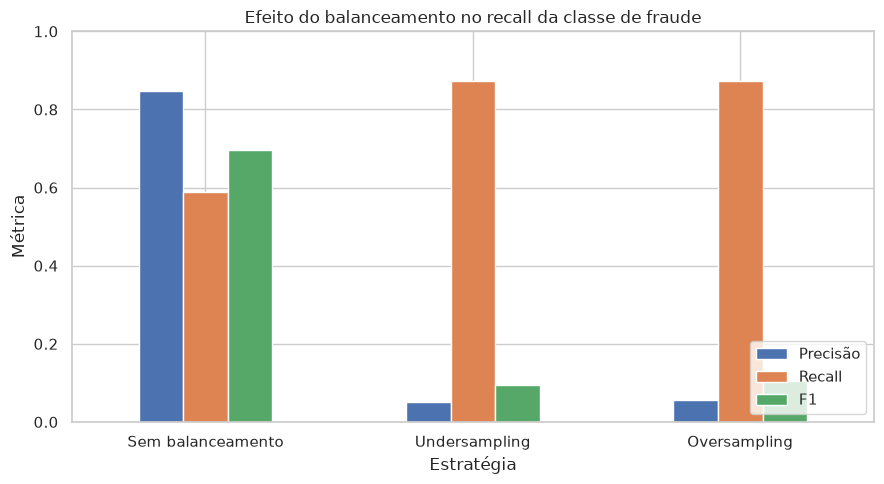

In [29]:
fig, ax = plt.subplots(figsize=(9, 5))
tabela_amostragem.set_index("Estratégia")[["Precisão", "Recall", "F1"]].plot(
    kind="bar",
    ax=ax,
    color=["#4c72b0", "#dd8452", "#55a868"],
)
ax.set_title("Efeito do balanceamento no recall da classe de fraude")
ax.set_ylabel("Métrica")
ax.set_ylim(0, 1)
ax.legend(loc="lower right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("images/10_amostragem.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Conclusões

- O desbalanceamento muda a pergunta: não é "quanto o modelo acerta?", e sim "quantas fraudes ele encontra e a que custo?".
- A remoção de duplicatas antes do split evita que a mesma transação apareça no treino e no teste.
- A comparação entre os modelos usa precisão, recall, F1, ROC AUC e PR AUC da classe de fraude.
- O limiar de 0,3 não ajuda todos os modelos: no XGBoost original não muda o recall e reduz a precisão, mas no Random Forest e no XGBoost ajustado ele aumenta o recall.
- O `GridSearchCV` otimiza o recall usando o limiar padrão de 0,5; uma evolução é usar um scorer customizado no limiar escolhido.
- O SHAP mostra quais variáveis mais empurraram cada decisão, o que ajuda a explicar o modelo para áreas de negócio e compliance.
- Undersampling e oversampling aumentam o recall, mas com precisão muito baixa. O melhor caminho foi o XGBoost com peso de classe e ajuste de limiar.

In [30]:
melhor_recall = tabela_modelos["Recall"].idxmax()
melhor_f1 = tabela_modelos["F1"].idxmax()
modelo_final_nome = "XGBoost GridSearchCV (limiar 0,3)"
modelo_final = tabela_finais.loc[modelo_final_nome]

print(f"Modelo escolhido: {modelo_final_nome}")
print(f"  Precisão: {modelo_final['Precisão']:.4f}")
print(f"  Recall: {modelo_final['Recall']:.4f}")
print(f"  F1: {modelo_final['F1']:.4f}")
print(f"  PR AUC: {modelo_final['PR AUC']:.4f}")
print()
print(f"Maior recall no limiar 0,5: {melhor_recall}")
print(f"  Recall: {tabela_modelos.loc[melhor_recall, 'Recall']:.4f}")
print(f"  Precisão: {tabela_modelos.loc[melhor_recall, 'Precisão']:.4f}")
print(f"  F1: {tabela_modelos.loc[melhor_recall, 'F1']:.4f}")
print()
print(f"Maior F1 no limiar 0,5: {melhor_f1}")
print(f"  Precisão: {tabela_modelos.loc[melhor_f1, 'Precisão']:.4f}")
print(f"  Recall: {tabela_modelos.loc[melhor_f1, 'Recall']:.4f}")
print(f"  F1: {tabela_modelos.loc[melhor_f1, 'F1']:.4f}")

Modelo escolhido: XGBoost GridSearchCV (limiar 0,3)
  Precisão: 0.8404
  Recall: 0.8316
  F1: 0.8360
  PR AUC: 0.8345

Maior recall no limiar 0,5: Regressão Logística
  Recall: 0.8737
  Precisão: 0.0554
  F1: 0.1042

Maior F1 no limiar 0,5: XGBoost
  Precisão: 0.8556
  Recall: 0.8105
  F1: 0.8324
